<a href="https://colab.research.google.com/github/hizocar/machine_learning_egei/blob/main/docs/notebooks/s04_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 4 · The ML Pipeline, in the Right Order

**The case.** You work for a social-policy unit. Programmes must reach poor households, but income is
hard to verify: people under-report it, and checking it is expensive. So governments predict welfare
from things that *are* easy to observe — schooling, household size, age. This is called a **proxy
means test**, and Chile's *Registro Social de Hogares* and Mexico's *Progresa* are built on it.

**Today's question.** How well can we predict a household's (log) income per capita from three
observable characteristics — and how do we *know* the number we report is honest?

**What you already know** (Sessions 1–3): pandas, train/test split, KNN, linear regression, the
bias–variance trade-off.
**What is new today:** scaling, `Pipeline`, k-fold cross-validation, and three kinds of data leakage.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import root_mean_squared_error

DATA_URL = "https://raw.githubusercontent.com/hizocar/machine_learning_egei/main/docs/data/casen_households.csv"
LOCAL = Path("../data/casen_households.csv")
df = pd.read_csv(LOCAL if LOCAL.exists() else DATA_URL)
df.shape

(15000, 25)

## 1. Define the population and the target

Each row is one household from CASEN 2022. A handful report zero income; the logarithm is not
defined there, so we leave them out *and say so* — every row we drop is a decision.

We model `log(income per capita)` because income is very skewed: a few households earn a hundred
times the median, and on the raw scale they would dominate the error.

households with zero income: 37


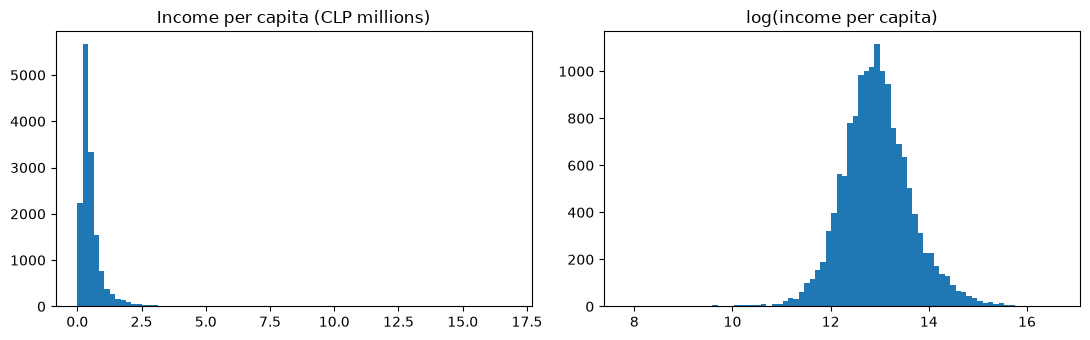

In [2]:
print("households with zero income:", (df["income_per_capita"] <= 0).sum())

FEATURES = ["head_age", "head_schooling_years", "household_size"]
reg = df[df["income_per_capita"] > 0].dropna(subset=FEATURES).copy()
reg["log_income_pc"] = np.log(reg["income_per_capita"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(reg["income_per_capita"] / 1e6, bins=80)
ax[0].set_title("Income per capita (CLP millions)")
ax[1].hist(reg["log_income_pc"], bins=80)
ax[1].set_title("log(income per capita)")
plt.tight_layout()

## 2. Split first — before you look at anything else

The test set is the stand-in for households the model has never seen. From this line on, **nothing
we decide may use it** — not the scaling, not the choice of k, not the choice of features.

In [3]:
X = reg[FEATURES]
y = reg["log_income_pc"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

# The baseline every model must beat: predict the training mean for everybody.
baseline = root_mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"Baseline RMSE: {baseline:.3f}")

(11912, 3) (2978, 3)
Baseline RMSE: 0.707


## 3. Recap of Session 3: linear regression and KNN

In [4]:
ols = LinearRegression().fit(X_train, y_train)
print(f"Linear regression  test RMSE: {root_mean_squared_error(y_test, ols.predict(X_test)):.3f}")

for k in [1, 100]:
    knn = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    tr = root_mean_squared_error(y_train, knn.predict(X_train))
    te = root_mean_squared_error(y_test, knn.predict(X_test))
    print(f"KNN k={k:<3}  train RMSE {tr:.3f}   test RMSE {te:.3f}")

Linear regression  test RMSE: 0.610
KNN k=1    train RMSE 0.659   test RMSE 0.820


KNN k=100  train RMSE 0.579   test RMSE 0.592


With k = 1 the training error is low and the test error is the worst of all: the model memorises.
That is the bias–variance trade-off from Session 3, now on real data.

## 4. New tool #1 — scaling

KNN decides who is "near" using distances. Age runs from about 15 to 100, schooling from 0 to 25,
household size from 1 to 13. Without scaling, a 10-year age gap counts as much as 10 extra years of
schooling — the variable with the widest range dominates the distance just because of its units.

`StandardScaler` rescales each column to mean 0 and standard deviation 1. It *learns* the mean and the
standard deviation — so, like a model, it must learn them **from the training set only**.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)          # learns mean and sd from TRAIN only
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)              # applies the train mean/sd to test

pd.DataFrame({"mean learned": scaler.mean_, "sd learned": scaler.scale_}, index=FEATURES).round(2)

,mean learned,sd learned
head_age,54.5,16.48
head_schooling_years,10.7,4.54
household_size,2.8,1.46


### ✋ Check the worked example from the session page

The page computes, by hand, the two nearest neighbours of a new household (age 40, 12 years of
schooling, 4 members) among four households A–D, with and without scaling. Reproduce it here, and
compare the result with your paper version.

In [6]:
toy = pd.DataFrame({"head_age": [40, 49, 41, 55], "head_schooling_years": [17, 12, 6, 12],
                    "household_size": [4, 4, 4, 3], "log_income_pc": [13.5, 12.8, 12.2, 12.9]},
                   index=list("ABCD"))
new = np.array([40, 12, 4])
sd_round = np.array([16.5, 4.5, 1.5])                       # the rounded sds used on the page

toy["dist_raw"] = np.sqrt(((toy[FEATURES] - new) ** 2).sum(axis=1)).round(2)
toy["dist_scaled"] = np.sqrt((((toy[FEATURES] - new) / sd_round) ** 2).sum(axis=1)).round(2)
for col in ["dist_raw", "dist_scaled"]:
    nearest = toy.nsmallest(2, col)
    print(f"{col:12s} nearest: {list(nearest.index)}  prediction: {nearest['log_income_pc'].mean():.2f}"
          f"  (≈ CLP {np.exp(nearest['log_income_pc'].mean()):,.0f} per person)")
toy

dist_raw     nearest: ['A', 'C']  prediction: 12.85  (≈ CLP 380,789 per person)
dist_scaled  nearest: ['B', 'A']  prediction: 13.15  (≈ CLP 514,011 per person)


,head_age,head_schooling_years,household_size,log_income_pc,dist_raw,dist_scaled
A,40,17,4,13.5,5.00,1.11
B,49,12,4,12.8,9.00,0.55
C,41,6,4,12.2,6.08,1.33
D,55,12,3,12.9,15.03,1.13


## 5. New tool #2 — the `Pipeline`

Fitting the scaler and the model by hand works, but you have to remember the order every time — and
in cross-validation you would have to repeat it inside every fold. A `Pipeline` glues the steps into
one object: `.fit()` fits each step on the data it receives, in order, and `.predict()` applies them.

In [7]:
from sklearn.pipeline import make_pipeline

model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=100))
model.fit(X_train, y_train)
print(f"Scaled KNN (k=100)  test RMSE: {root_mean_squared_error(y_test, model.predict(X_test)):.3f}")
model

Scaled KNN (k=100)  test RMSE: 0.582


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['head_age','head_schooling_years','household_size']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 6. New tool #3 — k-fold cross-validation, to choose k honestly

Which k should we use? The tempting answer — "try several and keep the best **test** score" — is a
leak: the test set would be choosing the model, and its score would no longer be honest.

Instead we split the **training set** into 5 folds. Each fold takes a turn as a mini-test set while
the other 4 train the pipeline. Because the scaler lives inside the pipeline, it is refitted on the 4
training folds every time — no fold ever sees its own validation data.

In [8]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for k in [1, 5, 25, 50, 100, 200, 400]:
    pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    scores = -cross_val_score(pipe, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    rows.append({"k": k, "cv_rmse_mean": scores.mean(), "cv_rmse_sd": scores.std()})
cv_table = pd.DataFrame(rows).round(3)
cv_table

,k,cv_rmse_mean,cv_rmse_sd
0,1,0.796,0.012
1,5,0.616,0.003
2,25,0.578,0.004
3,50,0.574,0.005
4,100,0.572,0.005
5,200,0.573,0.005
6,400,0.576,0.004


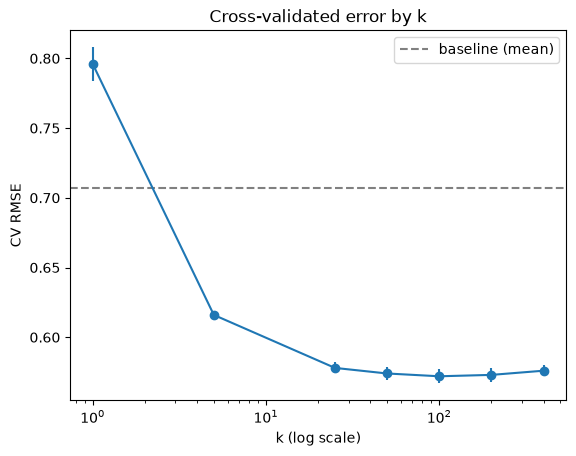

In [9]:
plt.errorbar(cv_table["k"], cv_table["cv_rmse_mean"], yerr=cv_table["cv_rmse_sd"], marker="o")
plt.axhline(baseline, ls="--", c="grey", label="baseline (mean)")
plt.xscale("log"); plt.xlabel("k (log scale)"); plt.ylabel("CV RMSE"); plt.legend()
plt.title("Cross-validated error by k");

The curve flattens from about k = 50; we pick **k = 100**. Only now — once, at the very end — do we
look at the test set.

In [10]:
final = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=100)).fit(X_train, y_train)
print(f"Final test RMSE: {root_mean_squared_error(y_test, final.predict(X_test)):.3f}  (baseline {baseline:.3f})")

Final test RMSE: 0.582  (baseline 0.707)


## 7. Leakage hunt

Leakage is any way information that would not be available at prediction time reaches the model.
Three cases, on our own data.

### Leak A — scaling before the split

In [11]:
X_all_scaled = StandardScaler().fit_transform(X)          # WRONG: the scaler sees the test rows
a_tr, a_te, b_tr, b_te = train_test_split(X_all_scaled, y, test_size=0.2, random_state=42)
leaky = KNeighborsRegressor(n_neighbors=100).fit(a_tr, b_tr)
print(f"Scale-then-split test RMSE: {root_mean_squared_error(b_te, leaky.predict(a_te)):.3f}")

Scale-then-split test RMSE: 0.582


Almost identical to the honest pipeline. With 15,000 rows, a mean and a standard deviation barely
change when you add the test rows, so **this particular leak is small here**. We still never do it:
with small data, or with steps that learn more from the data (imputers, encoders that use the target,
feature selection), the same mistake inflates scores badly — and the pipeline prevents it for free.

### Leak B — a feature built from the target

CASEN also publishes each household's **income decile**. It is tempting: it is "just a category".

In [12]:
X_leak = reg[FEATURES + ["income_decile"]]
l_tr, l_te, _, _ = train_test_split(X_leak, y, test_size=0.2, random_state=42)
leak_model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=25)).fit(l_tr, y_train)
print(f"With income_decile — test RMSE: {root_mean_squared_error(y_test, leak_model.predict(l_te)):.3f}")

With income_decile — test RMSE: 0.313


The error falls from ≈ 0.58 to ≈ 0.31. Nothing is wrong with the code — the decile is **computed from
income**, the thing we are trying to predict. In a proxy means test you would never have it: if you
knew the decile, you would not need the model. The question to ask about every feature is:
*would I have this value at the moment I need the prediction?*

### Leak C — choosing the model with the test set

If we had picked k by looking at test scores, the test score would be the best of many tries — an
optimistic number. That is why we chose k with cross-validation on the training set (section 6).

### One more to keep in mind — the same unit on both sides

Our rows are households. If the rows were *people*, members of the same household would land in both
train and test, and the model would "recognise" their shared income. Make the unit of analysis the
unit you will predict for, or split by group (`GroupKFold`).

## 8. With your assistant

```text
Here is my scikit-learn code (paste it). Review it for data leakage.
For every transformation, say whether it is fitted before or after the train/test split.
For every feature, say whether it would be available at prediction time in a proxy means test.
List the problems first, then the corrected code.
```
Then check its answer against this notebook. Did it catch `income_decile`? Did it flag anything that
is not actually a problem?

## 9. Exercises

1. Add `head_weekly_hours` as a fourth feature. What do its missing values mean? (Hint: look at
   `head_activity`.) Fill them with `.fillna()` using the value that matches that meaning. Why is a
   fixed rule like this safe to apply before the split, while a learned mean would not be?
2. Repeat the cross-validation with `LinearRegression` instead of KNN. Which would you choose, and why?
3. Write two sentences explaining to a policymaker why a model with RMSE 0.31 should not be used.